### Types of Continuous Probability Distributions

1. Gaussian / Normal Distribution (`np.random.normal`)
2. Continuous Uniform Distribution (`np.random.uniform`)
3. Exponential Distribution (`np.random.exponential`)
4. Beta Distribution (`np.random.beta`)
5. Gamma Distribution (`np.random.gamma`)

---

In [9]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
plt.style.use(
    'seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default'
)
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)


## 1. Gaussian / Normal Distribution (`np.random.normal`)

- The fundamental distribution in Statistics and Machine Learning, closely related to the Central Limit Theorem (CLT).
- It is a continuous probability distribution with a symmetric, bell-shaped curve.
- Most values are concentrated around the mean, while fewer values occur towards the tails.
- Used for modeling measurement errors, feature standardization, weight initialization in neural networks, and residual analysis.

### Real-World Examples

- Students' examination marks.
- Human heights and weights (approximately normal in suitable populations).
- Measurement errors in scientific experiments.
- Blood pressure measurements.

### Mathematical Formula

The Probability Density Function (PDF) for a Normal Distribution is:

$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

Where:

- $f(x)$ = Probability Density Function (PDF).
- $x$ = Value of the continuous random variable.
- $\mu$ = Population mean / expected value.
- $\sigma$ = Population standard deviation.
- $\sigma^2$ = Population variance.
- $\pi$ = Mathematical constant (approximately 3.14159).
- $e$ = Euler's number (approximately 2.71828).


### Important Properties

- The curve is symmetric around the mean.
- Mean = Median = Mode.
- Total area under the PDF curve = 1.
- Approximately 68% of observations lie within $\mu \pm 1\sigma$.
- Approximately 95% of observations lie within $\mu \pm 2\sigma$.
- Approximately 99.7% of observations lie within $\mu \pm 3\sigma$.

=== 1. GAUSSIAN / NORMAL DISTRIBUTION OUTPUT ===
Target Parameters  : Mean (mu) = 0.00, Std Dev (sigma) = 1.50
Empirical Metrics  : Mean = 0.0015, Std Dev = 1.5014
Sample Range       : Min = -6.6984, Max = 6.7186



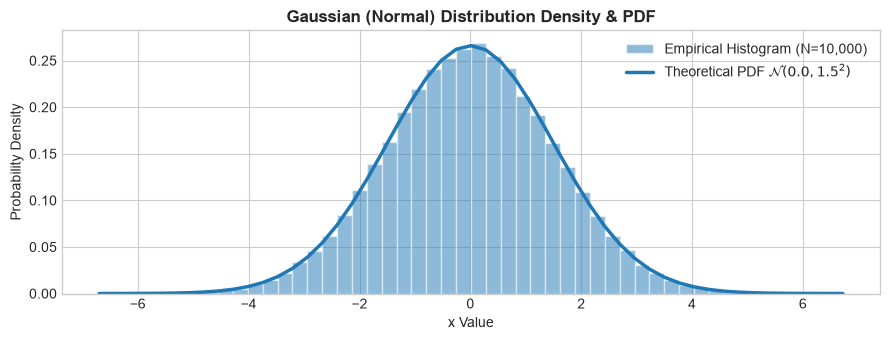

In [10]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
mu, sigma = 0.0, 1.5                                # Target mean=0, std_dev=1.5

# np.random.normal Function Parameters Explained:
# - loc=mu     : Mean (mu) centering the bell curve at 0.0
# - scale=sigma: Standard deviation (sigma) specifying distribution spread of 1.5
# - size=10000 : Total number of random floating-point values generated
samples_normal = np.random.normal(loc=mu, scale=sigma, size=100000)

empirical_mean = np.mean(samples_normal)
empirical_std = np.std(samples_normal)

print("=== 1. GAUSSIAN / NORMAL DISTRIBUTION OUTPUT ===")
print(f"Target Parameters  : Mean (mu) = {mu:.2f}, Std Dev (sigma) = {sigma:.2f}")
print(f"Empirical Metrics  : Mean = {empirical_mean:.4f}, Std Dev = {empirical_std:.4f}")
print(f"Sample Range       : Min = {samples_normal.min():.4f}, Max = {samples_normal.max():.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Normalizes histogram bin heights so total area under curve equals 1.0 (matches PDF scale)
# - bins=50: Number of equal-width discrete intervals across data range
# - alpha=0.5: Translucency level for transparent overlaying of line curves
# - color='#1f77b4': Standard muted blue
# - edgecolor='white': Sharp contrast borders between histogram bars
count, bins, ignored = plt.hist(samples_normal, bins=50, density=True, alpha=0.5, color='#1f77b4', edgecolor='white', label='Empirical Histogram (N=10,000)')


# what stats.norm.pdf does is compute the theoretical probability density function (PDF) values for the given bins based on the specified mean and standard deviation.
'''
simple example of pdf in theory

 


'''

# stats.norm.pdf Parameters Explained:
# - x (bins)   : Array of evaluation points along the x-axis derived from histogram bins
# - loc=mu     : Mean location parameter matching target mean
# - scale=sigma: Scale (standard deviation) parameter matching target spread
pdf_normal = stats.norm.pdf(bins, loc=mu, scale=sigma)
plt.plot(bins, pdf_normal, color='#1f77b4', linewidth=2.5, label=f'Theoretical PDF $\\mathcal{{N}}({mu}, {sigma}^2)$')

plt.title('Gaussian (Normal) Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('x Value')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()



## 2. Continuous Uniform Distribution (`np.random.uniform`)

- Models events where every outcome within a bounded interval is equally likely.
- Essential for baseline hyperparameter search, random initialization bounds (Xavier/He uniform), and Inverse Transform Sampling algorithms.

### Mathematical Formula

The Probability Density Function (PDF) for a Continuous Uniform Distribution is:

$$
f(x) =
\begin{cases}
\frac{1}{b-a}, & a \leq x \leq b \\
0, & \text{otherwise}
\end{cases}
$$


### Pronunciation & Symbol Guide

| Mathematical Symbol | Name | Pronunciation | Meaning |
|---|---|---|---|
| $f(x)$ | Function of x | Eff of x | Probability Density Function |
| $x$ | X | Eks | Continuous random variable |
| $a$ | Lower bound | Ay | Lower limit of the interval |
| $b$ | Upper bound | Bee | Upper limit of the interval |
| $\frac{1}{b-a}$ | One divided by b minus a | One over bee minus ay | Constant probability density |
| $b-a$ | Interval width | Bee minus ay | Difference between upper and lower limits |
| $\leq$ | Less than or equal to | Less than or equal to | Includes the boundary value |
| $=$ | Equal to | Equals | Equality |
| $\pi$ | Pi | Pie | Mathematical constant (3.14159) |
| $\in$ | Element of | In | Belongs to a set |
| $\mathbb{R}$ | Real numbers | R | Set of all real numbers |
| $\text{otherwise}$ | Otherwise | Otherwise | All values outside the specified interval |


=== 2. UNIFORM DISTRIBUTION OUTPUT ===
Interval Bounds    : [-2.00, 5.00]
Theoretical Mean   : 1.5000 | Empirical Mean: 1.5119
Theoretical Var    : 4.0833 | Empirical Var : 4.1047



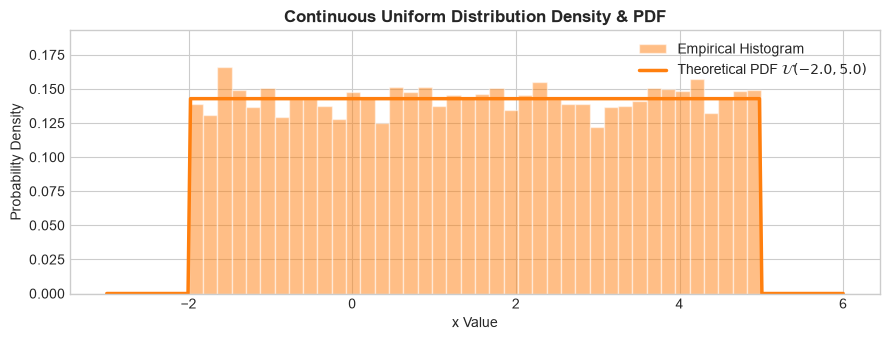

In [11]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
a, b = -2.0, 5.0                                    # Interval [-2.0, 5.0]

# np.random.uniform Function Parameters Explained:
# - low=a     : Lower boundary limit of interval (-2.0 inclusive)
# - high=b    : Upper boundary limit of interval (+5.0 exclusive/inclusive)
# - size=10000: Total number of random uniformly spaced samples to draw
samples_uniform = np.random.uniform(low=a, high=b, size=10000)

theoretical_mean = (a + b) / 2.0
theoretical_var = ((b - a)**2) / 12.0

print("=== 2. UNIFORM DISTRIBUTION OUTPUT ===")
print(f"Interval Bounds    : [{a:.2f}, {b:.2f}]")
print(f"Theoretical Mean   : {theoretical_mean:.4f} | Empirical Mean: {np.mean(samples_uniform):.4f}")
print(f"Theoretical Var    : {theoretical_var:.4f} | Empirical Var : {np.var(samples_uniform):.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Heights scaled so integral equals 1.0
# - bins=40: Discrete intervals across uniform interval
# - alpha=0.5: Translucency level
# - color='#ff7f0e': Safety orange
# - edgecolor='white': Sharp separation lines between bars
plt.hist(samples_uniform, bins=40, density=True, alpha=0.5, color='#ff7f0e', edgecolor='white', label='Empirical Histogram')

x_axis = np.linspace(a - 1.0, b + 1.0, 300)

# stats.uniform.pdf Parameters Explained:
# - x (x_axis)   : Extended continuous range spanning beyond bounds [-3, 6]
# - loc=a        : Starting offset point (lower boundary a = -2.0)
# - scale=(b - a): Interval width (5.0 - (-2.0) = 7.0), setting density height to 1/7
pdf_uniform = stats.uniform.pdf(x_axis, loc=a, scale=b - a)

# Plot formatting parameters detailed:
# - color='#ff7f0e': Safety orange line
# - linewidth=2.5: Line width for distinct step visibility
plt.plot(x_axis, pdf_uniform, color='#ff7f0e', linewidth=2.5, label=f'Theoretical PDF $\\mathcal{{U}}({a}, {b})$')

plt.title('Continuous Uniform Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('x Value')
plt.ylabel('Probability Density')
plt.ylim(0, 1.0 / (b - a) + 0.05)                    # Set vertical axis slightly above box height
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 3. Exponential Distribution (`np.random.exponential`)

- Models the continuous time interval between independent Poisson point events (e.g., time between customer arrivals, server request delays, component failure lifespans).
- It is commonly used to model waiting times between consecutive independent events occurring at a constant average rate.

### Mathematical Formula

The Probability Density Function (PDF) of an Exponential Distribution is:

$$
f(x) =
\begin{cases}
\lambda e^{-\lambda x}, & x \geq 0 \\
0, & x < 0
\end{cases}
$$

Given rate parameter $\lambda$ or scale parameter $\beta$ (mean duration):

$$
\beta = \frac{1}{\lambda}
$$

### Pronunciation & Symbol Guide

| Mathematical Symbol | Name | Pronunciation | Meaning |
|---|---|---|---|
| $f(x)$ | Function of x | Eff of x | Probability Density Function |
| $x$ | X | Eks | Continuous random variable (waiting time) |
| $\lambda$ | Lambda | Lam-duh | Event rate parameter |
| $\beta$ | Beta | Bay-tuh | Scale parameter / mean waiting time |
| $e$ | Euler's number | Oy-ler's number | Mathematical constant (approximately 2.71828) |
| $e^{-\lambda x}$ | Exponential term | E to the minus lambda x | Exponential decay factor |
| $\lambda x$ | Lambda x | Lam-duh eks | Product of rate and waiting time |
| $\frac{1}{\lambda}$ | One over lambda | One divided by lambda | Mean waiting time |
| $\geq$ | Greater than or equal to | Greater than or equal to | Includes the boundary value |
| $<$ | Less than | Less than | Strictly smaller than |
| $=$ | Equal to | Equals | Equality |
| $0$ | Zero | Zero | Lower boundary of waiting time |

### Parameters

- `scale`: `float` — The scale parameter $\beta = \frac{1}{\lambda}$ (mean value of the distribution).
- `size`: `int` or `tuple` — Output shape, specifying the number or dimensions of random samples.

=== 3. EXPONENTIAL DISTRIBUTION OUTPUT ===
Target Scale (beta = 1/lambda) : 2.00
Empirical Mean                : 2.0677
Empirical Variance            : 4.3259 (Theoretical: 4.00)
Median Waiting Time           : 1.4334



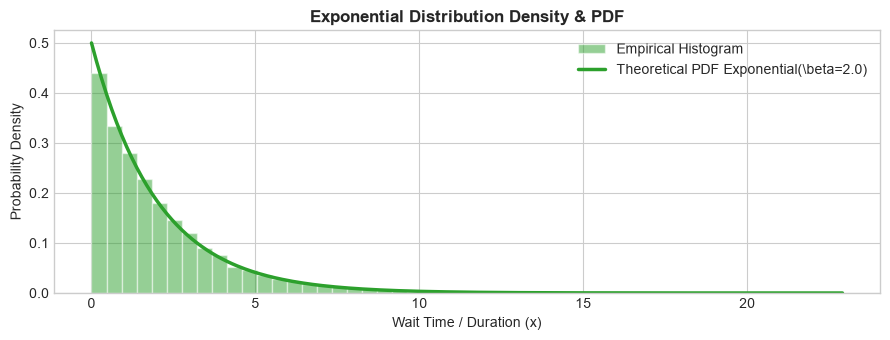

In [12]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
beta_scale = 2.0                                    # Mean duration scale beta = 2.0 (Rate lambda = 0.5)

# np.random.exponential Function Parameters Explained:
# - scale=beta_scale: Scale parameter beta = 1/lambda representing average duration between arrivals (2.0)
# - size=10000       : Number of random waiting times sampled
samples_exp = np.random.exponential(scale=beta_scale, size=10000)

print("=== 3. EXPONENTIAL DISTRIBUTION OUTPUT ===")
print(f"Target Scale (beta = 1/lambda) : {beta_scale:.2f}")
print(f"Empirical Mean                : {np.mean(samples_exp):.4f}")
print(f"Empirical Variance            : {np.var(samples_exp):.4f} (Theoretical: {beta_scale**2:.2f})")
print(f"Median Waiting Time           : {np.median(samples_exp):.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Heights scaled to yield unit total area
# - bins=50: Discrete intervals along exponential tail
# - alpha=0.5: Translucency level
# - color='#2ca02c': Forest green
# - edgecolor='white': Sharp boundary outlines
plt.hist(samples_exp, bins=50, density=True, alpha=0.5, color='#2ca02c', edgecolor='white', label='Empirical Histogram')

x_exp = np.linspace(0, np.max(samples_exp), 300)

# stats.expon.pdf Parameters Explained:
# - x (x_exp)         : Array of positive continuous evaluation values starting at 0
# - scale=beta_scale  : Scale parameter beta = 1/lambda matching mean duration (2.0)
pdf_exp = stats.expon.pdf(x_exp, scale=beta_scale)

# Plot formatting parameters detailed:
# - color='#2ca02c': Forest green line curve
# - linewidth=2.5: Line width
plt.plot(x_exp, pdf_exp, color='#2ca02c', linewidth=2.5, label=rf'Theoretical PDF Exponential(\beta={beta_scale})')

plt.title('Exponential Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('Wait Time / Duration (x)')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 4. Beta Distribution (`np.random.beta`)

- A continuous distribution bounded on the closed interval $[0,1]$.
- Widely used in Bayesian inference as a conjugate prior for binomial probabilities, modeling conversion rates, probabilities, and proportion uncertainties.

### Mathematical Formula

For shape parameters $\alpha$ and $\beta$, the Probability Density Function (PDF) is:

$$
f(x;\alpha,\beta) =
\frac{x^{\alpha-1}(1-x)^{\beta-1}}
{B(\alpha,\beta)}
$$

where $0 \leq x \leq 1$ and $\alpha,\beta > 0$.

The Beta function $B(\alpha,\beta)$ normalizes the total probability area to $1$:

$$
B(\alpha,\beta) =
\frac{\Gamma(\alpha)\Gamma(\beta)}
{\Gamma(\alpha+\beta)}
$$

### Pronunciation & Symbol Guide

| Mathematical Symbol | Name | Pronunciation | Meaning |
|---|---|---|---|
| $f(x;\alpha,\beta)$ | Beta density function | Eff of x; alpha, beta | Probability density for a given x |
| $x$ | X | Eks | Continuous random variable between 0 and 1 |
| $\alpha$ | Alpha | Al-fuh | First shape parameter governing concentration near 0 |
| $\beta$ | Beta | Bay-tuh | Second shape parameter governing concentration near 1 |
| $B(\alpha,\beta)$ | Beta function | Capital Bay-tuh | Normalizing function for the distribution |
| $\Gamma(\alpha)$ | Gamma function | Capital Gam-muh | Generalization of factorial |
| $\Gamma(\beta)$ | Gamma function | Capital Gam-muh | Gamma function evaluated at beta |
| $\alpha+\beta$ | Alpha plus beta | Al-fuh plus bay-tuh | Sum of the two shape parameters |
| $\alpha-1$ | Alpha minus one | Al-fuh minus one | Exponent of x |
| $\beta-1$ | Beta minus one | Bay-tuh minus one | Exponent of (1-x) |
| $1-x$ | One minus x | One minus eks | Distance from x to the upper boundary |
| $0 \leq x \leq 1$ | Interval condition | Zero less than or equal to x, less than or equal to one | Allowed range of x |
| $\alpha,\beta > 0$ | Positive parameters | Alpha and beta greater than zero | Both shape parameters must be positive |
| $[0,1]$ | Closed interval | Zero to one, inclusive | Interval containing both endpoints |
| $\pi$ | Pi | Pie | Mathematical constant (approximately 3.14159) |
| $=$ | Equal to | Equals | Equality |
| $\times$ | Multiplication | Times | Multiplication operation |

### Parameters

- `a`: `float` — First shape parameter ($\alpha$).
- `b`: `float` — Second shape parameter ($\beta$).
- `size`: `int` or `tuple` — Output shape, specifying the number or dimensions of random samples.

=== 4. BETA DISTRIBUTION OUTPUT ===
Shape Parameters   : alpha = 2.0, beta = 5.0
Theoretical Mean   : 0.2857
Empirical Mean     : 0.2828
Sample Domain      : [0.0022, 0.8908] (Bounded in [0, 1])



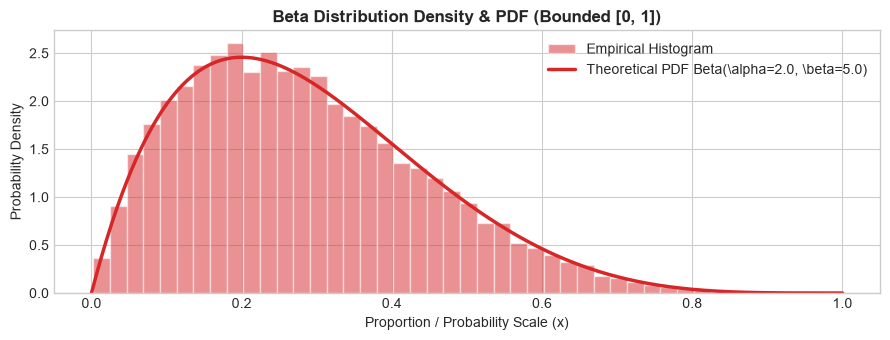

In [13]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
alpha_param, beta_param = 2.0, 5.0                  # Alpha=2 (skewed right towards 0)

# np.random.beta Function Parameters Explained:
# - a=alpha_param : Alpha shape parameter (> 0), controlling probability mass towards 1.0
# - b=beta_param  : Beta shape parameter (> 0), controlling probability mass towards 0.0
# - size=10000    : Number of random probability values sampled within bounded domain [0, 1]
samples_beta = np.random.beta(a=alpha_param, b=beta_param, size=10000)

theoretical_beta_mean = alpha_param / (alpha_param + beta_param)

print("=== 4. BETA DISTRIBUTION OUTPUT ===")
print(f"Shape Parameters   : alpha = {alpha_param:.1f}, beta = {beta_param:.1f}")
print(f"Theoretical Mean   : {theoretical_beta_mean:.4f}")
print(f"Empirical Mean     : {np.mean(samples_beta):.4f}")
print(f"Sample Domain      : [{samples_beta.min():.4f}, {samples_beta.max():.4f}] (Bounded in [0, 1])\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Scales bin heights so cumulative area equals 1.0
# - bins=40: Discrete intervals across [0, 1] range
# - alpha=0.5: Translucency level
# - color='#d62728': Crimson red
# - edgecolor='white': Sharp boundary outlines
plt.hist(samples_beta, bins=40, density=True, alpha=0.5, color='#d62728', edgecolor='white', label='Empirical Histogram')

x_beta = np.linspace(0, 1, 300)

# stats.beta.pdf Parameters Explained:
# - x (x_beta)     : Bounded evaluation grid strictly from 0 to 1
# - a=alpha_param  : First shape parameter alpha (2.0)
# - b=beta_param   : Second shape parameter beta (5.0)
pdf_beta = stats.beta.pdf(x_beta, a=alpha_param, b=beta_param)

# Plot formatting parameters detailed:
# - color='#d62728': Crimson red line curve
# - linewidth=2.5: Line width
plt.plot(x_beta, pdf_beta, color='#d62728', linewidth=2.5, label=rf'Theoretical PDF Beta(\alpha={alpha_param}, \beta={beta_param})')

plt.title('Beta Distribution Density & PDF (Bounded [0, 1])', fontsize=12, fontweight='bold')
plt.xlabel('Proportion / Probability Scale (x)')
plt.ylabel('Probability Density')
plt.xlim(-0.05, 1.05)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 5. Gamma Distribution (`np.random.gamma`)

- A continuous two-parameter family of right-skewed probability distributions.
- Generalizes the Exponential distribution to model the waiting time until multiple events occur; widely used in queueing models, rainfall modeling, financial risk analysis, and Poisson priors.

### Mathematical Formula

For shape $k$ (or $\alpha$) and scale $\theta$ (or $\beta$), the Probability Density Function (PDF) is:

$$
f(x;k,\theta) =
\frac{x^{k-1}e^{-x/\theta}}
{\Gamma(k)\theta^k},
\quad x \geq 0
$$

Where:

- $k > 0$ = Shape parameter.
- $\theta > 0$ = Scale parameter.
- $x \geq 0$ = Non-negative random variable.

### Pronunciation & Symbol Guide

| Mathematical Symbol | Name | Pronunciation | Meaning |
|---|---|---|---|
| $f(x;k,\theta)$ | Gamma density function | Eff of x; kay, thay-tuh | Probability density function |
| $x$ | X | Eks | Continuous random variable |
| $k$ | Shape parameter | Kay | Shape parameter controlling distribution profile |
| $\alpha$ | Alpha | Al-fuh | Alternative notation for shape parameter |
| $\theta$ | Theta | Thay-tuh | Scale parameter controlling stretch and dispersion |
| $\beta$ | Beta | Bay-tuh | Alternative notation sometimes used for scale |
| $\Gamma(k)$ | Gamma function | Capital Gam-muh of kay | Complete Gamma function evaluated at k |
| $e$ | Euler's number | Oy-ler's number | Mathematical constant (approximately 2.71828) |
| $e^{-x/\theta}$ | Exponential term | E to the minus x over theta | Exponential decay factor |
| $\theta^k$ | Theta to the power k | Thay-tuh to the kay | Scale parameter raised to the shape power |
| $x^{k-1}$ | X to the power k minus one | Eks to the kay minus one | Power term controlling the distribution shape |
| $k-1$ | K minus one | Kay minus one | Exponent of x |
| $x/\theta$ | X divided by theta | Eks over thay-tuh | Ratio of value to scale |
| $x \geq 0$ | Non-negative condition | X greater than or equal to zero | Valid range of the random variable |
| $k > 0$ | Positive shape | Kay greater than zero | Shape parameter must be positive |
| $\theta > 0$ | Positive scale | Thay-tuh greater than zero | Scale parameter must be positive |
| $\frac{a}{b}$ | Fraction | A divided by B | Division |
| $\pi$ | Pi | Pie | Mathematical constant (approximately 3.14159) |
| $=$ | Equal to | Equals | Equality |
| $\geq$ | Greater than or equal to | Greater than or equal to | Includes the boundary value |

### Parameters

- `shape`: `float` — Shape parameter ($k$ or $\alpha$), controlling the shape of the distribution.
- `scale`: `float` — Scale parameter ($\theta$), controlling the spread of the distribution.
- `size`: `int` or `tuple` — Output shape, specifying the number or dimensions of random samples.

=== 5. GAMMA DISTRIBUTION OUTPUT ===
Shape (k) = 3.0, Scale (theta) = 2.0
Theoretical Mean : 6.0000 | Empirical Mean : 6.0512
Theoretical Var  : 12.0000 | Empirical Var  : 12.1322



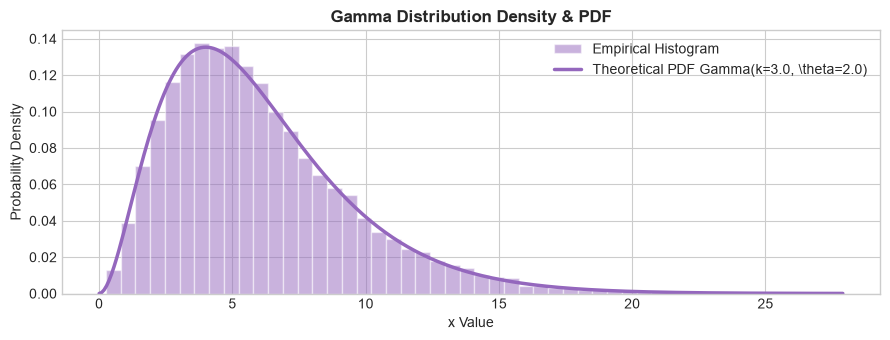

In [14]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
k_shape, theta_scale = 3.0, 2.0                      # k=3 (sum of 3 exponentials), theta=2

# np.random.gamma Function Parameters Explained:
# - shape=k_shape    : Shape parameter k (> 0) controlling profile skewness (3.0)
# - scale=theta_scale: Scale parameter theta (> 0) controlling horizontal stretching (2.0)
# - size=10000       : Number of continuous samples drawn from Gamma process
samples_gamma = np.random.gamma(shape=k_shape, scale=theta_scale, size=10000)

theoretical_gamma_mean = k_shape * theta_scale
theoretical_gamma_var = k_shape * (theta_scale**2)

print("=== 5. GAMMA DISTRIBUTION OUTPUT ===")
print(f"Shape (k) = {k_shape:.1f}, Scale (theta) = {theta_scale:.1f}")
print(f"Theoretical Mean : {theoretical_gamma_mean:.4f} | Empirical Mean : {np.mean(samples_gamma):.4f}")
print(f"Theoretical Var  : {theoretical_gamma_var:.4f} | Empirical Var  : {np.var(samples_gamma):.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Scales bin heights to form probability density area of 1.0
# - bins=50: Discrete interval count across continuous range
# - alpha=0.5: Translucency level
# - color='#9467bd': Muted purple
# - edgecolor='white': Sharp contrast outlines
plt.hist(samples_gamma, bins=50, density=True, alpha=0.5, color='#9467bd', edgecolor='white', label='Empirical Histogram')

x_gamma = np.linspace(0, np.max(samples_gamma), 300)

# stats.gamma.pdf Parameters Explained:
# - x (x_gamma)       : Positive evaluation points across continuous domain
# - a=k_shape         : SciPy uses parameter 'a' for shape parameter k (3.0)
# - scale=theta_scale : Scale parameter theta matching scale stretching (2.0)
pdf_gamma = stats.gamma.pdf(x_gamma, a=k_shape, scale=theta_scale)

# Plot formatting parameters detailed:
# - color='#9467bd': Muted purple line curve
# - linewidth=2.5: Line width
plt.plot(x_gamma, pdf_gamma, color='#9467bd', linewidth=2.5, label=rf'Theoretical PDF Gamma(k={k_shape}, \theta={theta_scale})')

plt.title('Gamma Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('x Value')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()